# EDA and Visualization: NYC Taxi Demand (Manhattan + Queens)

This notebook explores the processed zone-hour demand table, `features.csv` (one row per taxi zone per hour, 8 Sep 2025 to 28 Feb 2026).

| Section | GitHub issue |
|---|---|
| 1. Zone demand segmentation and predictability | #59 |
| 2. Demand over time and anomalies | #60 |
| 3. Weather impact on demand | #61 |
| 4. Feature relationships and correlations | #62 |

Every chart is saved in `EDA_doc/figures/` with its analysis ID in the file name (for example `C8_...png`). Summary tables are saved in `EDA_doc/tables/`.

## 0. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

In [2]:
# Dataset files (in the dataset/ folder next to the git folder)
DATA_DIR = "../../../dataset/archive"
FEATURES_FILE = DATA_DIR + "/features.csv"
ZONES_FILE = DATA_DIR + "/NYC-taxi-demand-Manhattan-Queens/kaggle_upload/taxi_zones_manhattan_queens.csv"

# Where charts and tables are saved
FIG_DIR = "../EDA_doc/figures"
TABLE_DIR = "../EDA_doc/tables"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)


def save_fig(name):
    # Save the current chart as a PNG and show it
    plt.tight_layout()
    plt.savefig(FIG_DIR + "/" + name + ".png", dpi=120, bbox_inches="tight")
    plt.show()

### Load the data

`features.csv` only has the zone ID, so the zone lookup file is joined to get the zone name, borough, service zone and the zone's centre point (latitude / longitude).

In [3]:
df = pd.read_csv(FEATURES_FILE, parse_dates=["pickup_hour"])
zones = pd.read_csv(ZONES_FILE)

print("Rows:", len(df))
print("Zones:", df["PULocationID"].nunique())
print("Period:", df["pickup_hour"].min(), "to", df["pickup_hour"].max())
print("Total trips:", df["trip_count"].sum())
df.head()

Rows: 576288
Zones: 138
Period: 2025-09-08 00:00:00 to 2026-02-28 23:00:00
Total trips: 21728117


,PULocationID,pickup_hour,trip_count,apparent_temperature,rain,snowfall,precipitation_probability,hour,day_of_week,month,is_weekend,is_holiday,trip_count_lag_1h,trip_count_lag_24h,trip_count_lag_168h,trip_count_roll_3h,trip_count_roll_24h
0,2,2025-09-08 00:00:00,0,13.8,0.0,0.0,0,0,0,9,False,False,0,0,0,0.0,0.0
1,2,2025-09-08 01:00:00,0,13.5,0.0,0.0,0,1,0,9,False,False,0,0,0,0.0,0.0
2,2,2025-09-08 02:00:00,0,13.5,0.0,0.0,0,2,0,9,False,False,0,0,0,0.0,0.0
3,2,2025-09-08 03:00:00,0,12.7,0.0,0.0,0,3,0,9,False,False,0,0,0,0.0,0.0
4,2,2025-09-08 04:00:00,0,12.3,0.0,0.0,0,4,0,9,False,False,0,0,0,0.0,0.0


In [4]:
# Rename the lookup columns so they match the feature table
zones = zones.rename(columns={
    "LocationID": "PULocationID",
    "Borough": "borough",
    "Zone": "zone_name",
})

# Some zone names repeat (e.g. the three island zones), so add the ID to the label
zones["zone_label"] = zones["zone_name"] + " (" + zones["PULocationID"].astype(str) + ")"

df = df.merge(zones, on="PULocationID", how="left")
zones.head()

,PULocationID,borough,zone_name,service_zone,latitude,longitude,zone_label
0,2,Queens,Jamaica Bay,Boro Zone,40.61675,-73.83130,Jamaica Bay (2)
1,4,Manhattan,Alphabet City,Yellow Zone,40.72375,-73.97697,Alphabet City (4)
2,7,Queens,Astoria,Boro Zone,40.76149,-73.91969,Astoria (7)
3,8,Queens,Astoria Park,Boro Zone,40.77856,-73.92309,Astoria Park (8)
4,9,Queens,Auburndale,Boro Zone,40.75103,-73.78795,Auburndale (9)


### Helper columns used in the EDA

These columns are only added in memory. The processed files are not changed.

In [5]:
df["date"] = df["pickup_hour"].dt.normalize()


def get_time_band(hour):
    if hour <= 4:
        return "Late night"
    elif hour <= 6:
        return "Early morning"
    elif hour <= 9:
        return "AM rush"
    elif hour <= 15:
        return "Midday"
    elif hour <= 19:
        return "PM rush"
    else:
        return "Evening"


df["time_band"] = df["hour"].apply(get_time_band)

# Day type: Holiday first, then Weekend, otherwise Weekday
df["day_type"] = "Weekday"
df.loc[df["is_weekend"] == True, "day_type"] = "Weekend"
df.loc[df["is_holiday"] == True, "day_type"] = "Holiday"

# The daylight saving hour has about double the normal trips (two clock hours in one)
df["is_dst_hour"] = df["pickup_hour"] == pd.Timestamp("2025-11-02 01:00:00")

df["is_zero"] = df["trip_count"] == 0

DAY_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
TIME_BANDS = ["Late night", "Early morning", "AM rush", "Midday", "PM rush", "Evening"]
BOROUGH_COLORS = {"Manhattan": "tab:blue", "Queens": "tab:orange"}

df[["pickup_hour", "zone_label", "borough", "trip_count", "time_band", "day_type"]].head()

,pickup_hour,zone_label,borough,trip_count,time_band,day_type
0,2025-09-08 00:00:00,Jamaica Bay (2),Queens,0,Late night,Weekday
1,2025-09-08 01:00:00,Jamaica Bay (2),Queens,0,Late night,Weekday
2,2025-09-08 02:00:00,Jamaica Bay (2),Queens,0,Late night,Weekday
3,2025-09-08 03:00:00,Jamaica Bay (2),Queens,0,Late night,Weekday
4,2025-09-08 04:00:00,Jamaica Bay (2),Queens,0,Late night,Weekday


### Zone summary table

One row per zone with its total trips, average trips per hour and share of hours with zero trips. Most of section 1 starts from this table.

In [6]:
zone_stats = df.groupby("PULocationID").agg(
    total_trips=("trip_count", "sum"),
    avg_per_hour=("trip_count", "mean"),
    zero_share=("is_zero", "mean"),
).reset_index()

zone_stats = zone_stats.merge(zones, on="PULocationID")
zone_stats = zone_stats.sort_values("total_trips", ascending=False).reset_index(drop=True)
zone_stats.head(10)

,PULocationID,total_trips,avg_per_hour,zero_share,borough,zone_name,service_zone,latitude,longitude,zone_label
0,237,1015744,243.233716,0.002155,Manhattan,Upper East Side South,Yellow Zone,40.76862,-73.96563,Upper East Side South (237)
1,161,921353,220.630508,0.000479,Manhattan,Midtown Center,Yellow Zone,40.75803,-73.97770,Midtown Center (161)
2,236,919941,220.292385,0.003831,Manhattan,Upper East Side North,Yellow Zone,40.78044,-73.95701,Upper East Side North (236)
3,132,844604,202.251916,0.003592,Queens,JFK Airport,Airports,40.64699,-73.78653,JFK Airport (132)
4,186,690164,165.269157,0.000479,Manhattan,Penn Station/Madison Sq West,Yellow Zone,40.74850,-73.99244,Penn Station/Madison Sq West (186)
5,162,683449,163.661159,0.000479,Manhattan,Midtown East,Yellow Zone,40.75669,-73.97236,Midtown East (162)
6,142,664996,159.242337,0.002395,Manhattan,Lincoln Square East,Yellow Zone,40.77363,-73.98153,Lincoln Square East (142)
7,230,648767,155.356082,0.001676,Manhattan,Times Sq/Theatre District,Yellow Zone,40.75982,-73.98420,Times Sq/Theatre District (230)
8,234,596884,142.931992,0.001437,Manhattan,Union Sq,Yellow Zone,40.74034,-73.99046,Union Sq (234)
9,79,590795,141.473898,0.000479,Manhattan,East Village,Yellow Zone,40.72762,-73.98594,East Village (79)


---
# 1. Zone demand segmentation and predictability (#59)

Where is the demand, how concentrated is it, what types of zones exist, and how predictable is each zone?

## C1. Zone ranking

Average trips per hour for the 20 busiest and the 20 quietest zones.

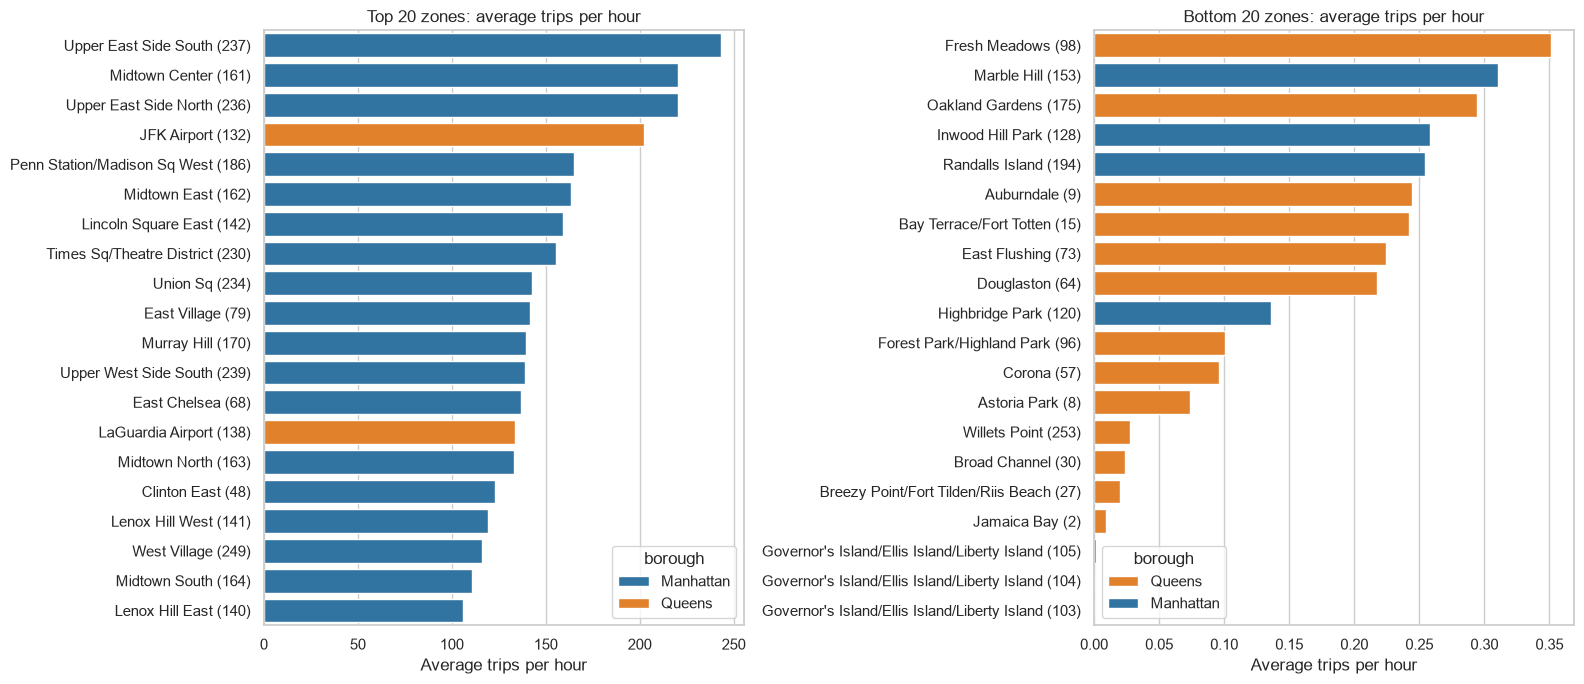

In [7]:
top20 = zone_stats.head(20)
bottom20 = zone_stats.tail(20)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(data=top20, y="zone_label", x="avg_per_hour", hue="borough",
            palette=BOROUGH_COLORS, dodge=False, ax=axes[0])
axes[0].set_title("Top 20 zones: average trips per hour")
axes[0].set_xlabel("Average trips per hour")
axes[0].set_ylabel("")

sns.barplot(data=bottom20, y="zone_label", x="avg_per_hour", hue="borough",
            palette=BOROUGH_COLORS, dodge=False, ax=axes[1])
axes[1].set_title("Bottom 20 zones: average trips per hour")
axes[1].set_xlabel("Average trips per hour")
axes[1].set_ylabel("")

save_fig("C1_top_bottom_zones")

In [8]:
# Totals by borough
borough_totals = zone_stats.groupby("borough")["total_trips"].sum()
print(borough_totals)
print()
print("Manhattan share of trips:", round(borough_totals["Manhattan"] / borough_totals.sum() * 100, 1), "%")
print()
print("Top 10 zones:")
print(zone_stats[["zone_label", "borough", "total_trips", "avg_per_hour"]].head(10).to_string(index=False))

borough
Manhattan    19679535
Queens        2048582
Name: total_trips, dtype: int64

Manhattan share of trips: 90.6 %

Top 10 zones:
                        zone_label   borough  total_trips  avg_per_hour
       Upper East Side South (237) Manhattan      1015744    243.233716
              Midtown Center (161) Manhattan       921353    220.630508
       Upper East Side North (236) Manhattan       919941    220.292385
                 JFK Airport (132)    Queens       844604    202.251916
Penn Station/Madison Sq West (186) Manhattan       690164    165.269157
                Midtown East (162) Manhattan       683449    163.661159
         Lincoln Square East (142) Manhattan       664996    159.242337
   Times Sq/Theatre District (230) Manhattan       648767    155.356082
                    Union Sq (234) Manhattan       596884    142.931992
                 East Village (79) Manhattan       590795    141.473898


**Finding (C1):** Manhattan has **90.6%** of the 21.7 M trips. The busiest zones are Upper East Side South (243 trips per hour), Midtown Center (221) and Upper East Side North (220). JFK Airport (202) is the only Queens zone in the top 10. The three island zones and Jamaica Bay have almost no pickups.

## C2. Demand concentration

- **Pareto chart:** share of all trips from each zone (bars) and the running total (line).
- **Lorenz curve and Gini coefficient:** 0 means every zone has the same demand, 1 means one zone has all of it.

Zones needed for 50% of trips: 16 of 138
Zones needed for 80% of trips: 33 of 138


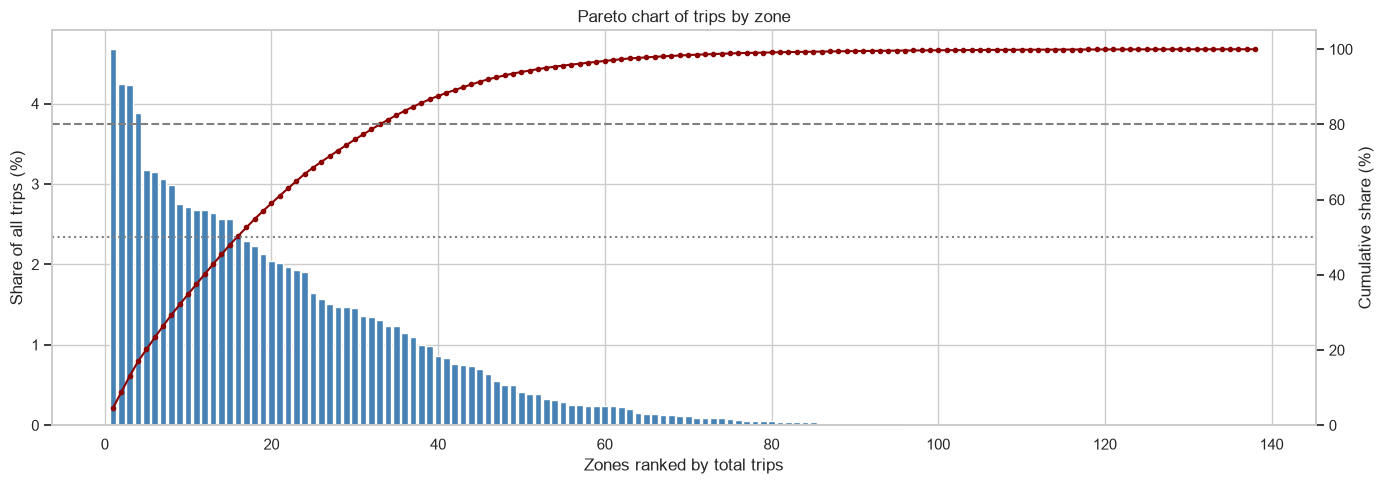

In [9]:
trips_sorted = zone_stats["total_trips"].values          # already sorted high to low
cum_share = trips_sorted.cumsum() / trips_sorted.sum()

zones_for_50 = (cum_share < 0.5).sum() + 1
zones_for_80 = (cum_share < 0.8).sum() + 1
print("Zones needed for 50% of trips:", zones_for_50, "of", len(zone_stats))
print("Zones needed for 80% of trips:", zones_for_80, "of", len(zone_stats))

fig, ax1 = plt.subplots(figsize=(14, 5))
x = np.arange(1, len(trips_sorted) + 1)
ax1.bar(x, trips_sorted / trips_sorted.sum() * 100, color="steelblue")
ax1.set_xlabel("Zones ranked by total trips")
ax1.set_ylabel("Share of all trips (%)")

ax2 = ax1.twinx()
ax2.plot(x, cum_share * 100, color="darkred", marker=".")
ax2.axhline(80, color="gray", linestyle="--")
ax2.axhline(50, color="gray", linestyle=":")
ax2.set_ylabel("Cumulative share (%)")
ax2.set_ylim(0, 105)
ax2.grid(False)

plt.title("Pareto chart of trips by zone")
save_fig("C2_pareto_chart")

All zones Gini: 0.709
Manhattan Gini: 0.486
Queens Gini: 0.844


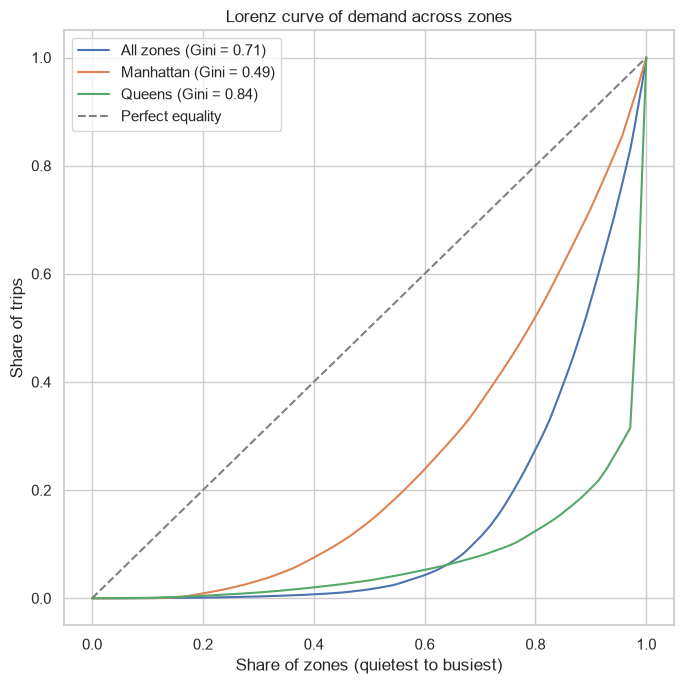

In [10]:
def gini(values):
    # Gini coefficient: 0 = perfectly equal, 1 = all demand in one zone
    values = np.sort(np.array(values, dtype=float))
    n = len(values)
    cum = np.cumsum(values)
    return (n + 1 - 2 * cum.sum() / cum[-1]) / n


def lorenz_points(values):
    values = np.sort(np.array(values, dtype=float))
    cum = np.cumsum(values) / values.sum()
    x = np.arange(0, len(values) + 1) / len(values)
    y = np.insert(cum, 0, 0)
    return x, y


plt.figure(figsize=(7, 7))
groups = {
    "All zones": zone_stats["total_trips"],
    "Manhattan": zone_stats[zone_stats["borough"] == "Manhattan"]["total_trips"],
    "Queens": zone_stats[zone_stats["borough"] == "Queens"]["total_trips"],
}
for name, values in groups.items():
    x, y = lorenz_points(values)
    g = gini(values)
    plt.plot(x, y, label=name + " (Gini = " + str(round(g, 2)) + ")")
    print(name, "Gini:", round(g, 3))

plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Perfect equality")
plt.xlabel("Share of zones (quietest to busiest)")
plt.ylabel("Share of trips")
plt.title("Lorenz curve of demand across zones")
plt.legend()
save_fig("C2_lorenz_curve")

**Finding (C2):** Demand is very concentrated. **16 of 138 zones (12%) make up half of all trips**, and 33 zones (24%) make up 80%. The Gini coefficient is 0.71 overall: 0.49 within Manhattan and 0.84 within Queens, where a few zones such as JFK Airport carry most of the borough's demand.

## C6. Demand maps by time band

Each bubble is a zone centre point. Bubble size is the average trips per hour in that time band. The 5 busiest zones in each band are labelled.

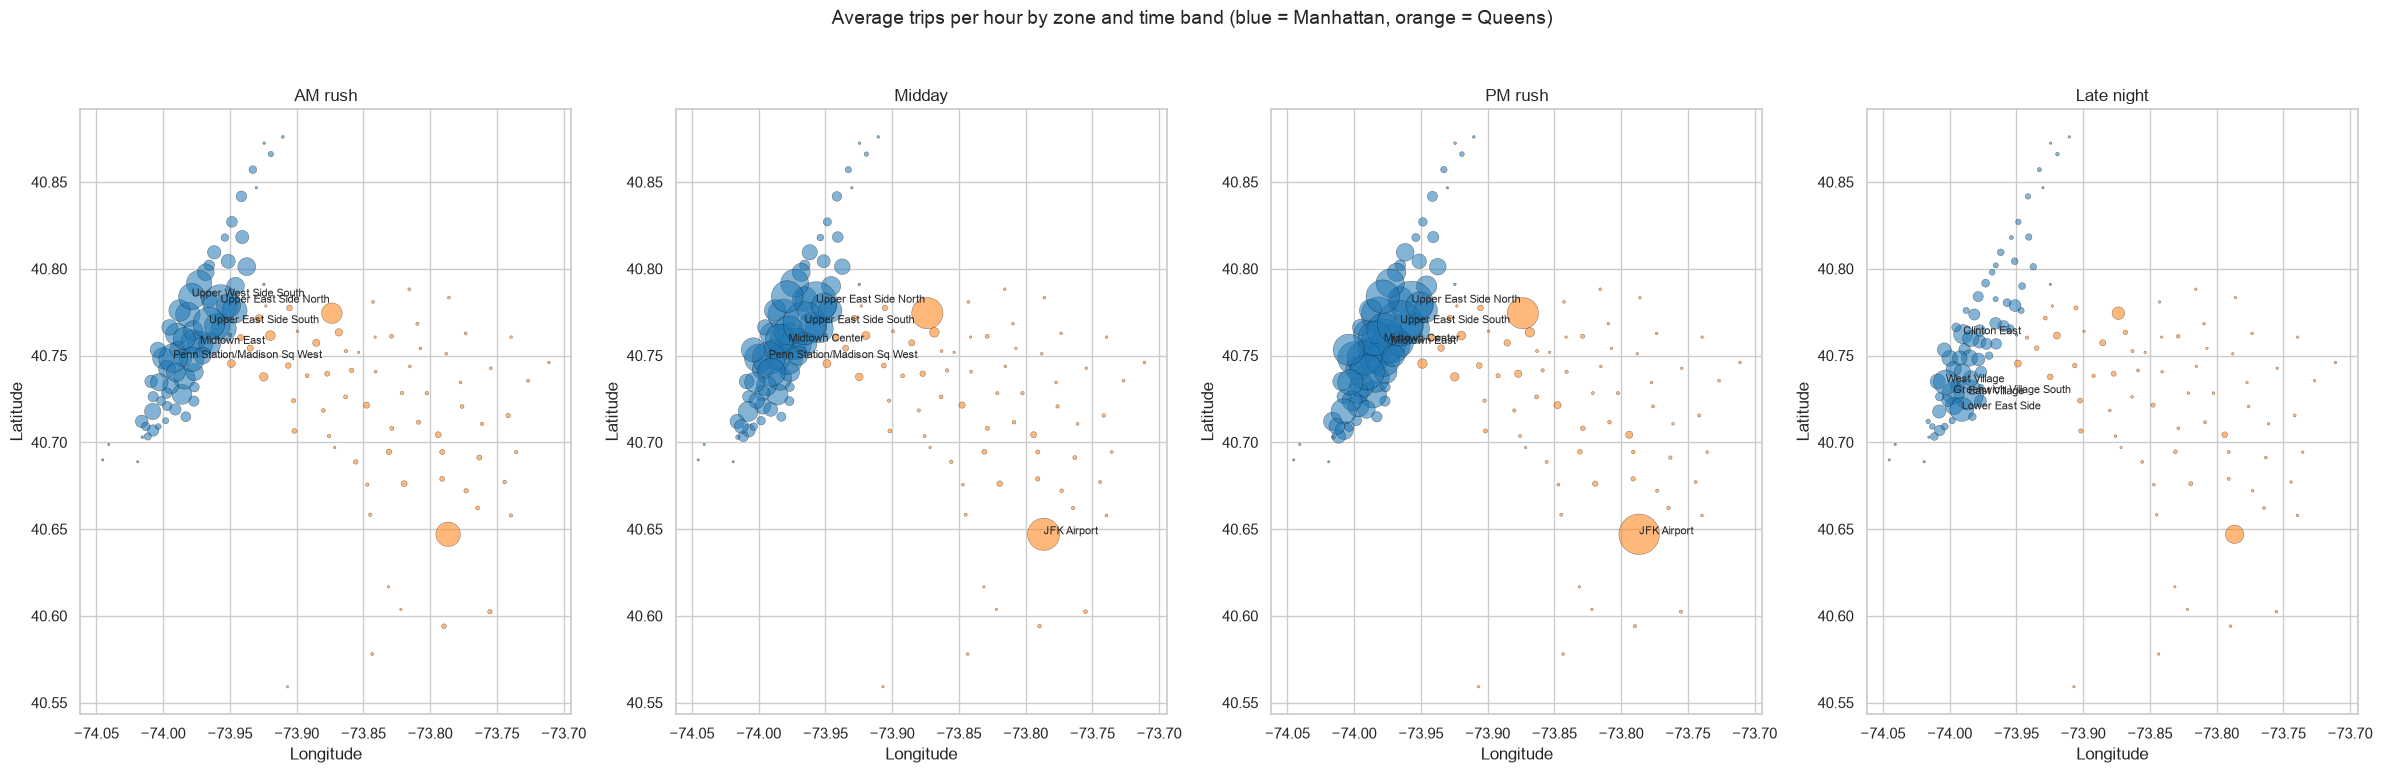

In [11]:
map_bands = ["AM rush", "Midday", "PM rush", "Late night"]

band_avg = df.groupby(["PULocationID", "time_band"])["trip_count"].mean().reset_index()
band_avg = band_avg.merge(zones, on="PULocationID")

fig, axes = plt.subplots(1, 4, figsize=(24, 8))
for i, band in enumerate(map_bands):
    ax = axes[i]
    data = band_avg[band_avg["time_band"] == band]
    ax.scatter(data["longitude"], data["latitude"],
               s=data["trip_count"] * 2.5 + 3,
               c=data["borough"].map(BOROUGH_COLORS),
               alpha=0.55, edgecolor="black", linewidth=0.3)

    top5 = data.sort_values("trip_count", ascending=False).head(5)
    for _, row in top5.iterrows():
        ax.annotate(row["zone_name"], (row["longitude"], row["latitude"]), fontsize=8)

    ax.set_title(band)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_aspect(1.3)

plt.suptitle("Average trips per hour by zone and time band (blue = Manhattan, orange = Queens)", fontsize=14)
save_fig("C6_demand_maps_by_time_band")

In [12]:
# Top 5 zones in each time band
for band in TIME_BANDS:
    data = band_avg[band_avg["time_band"] == band].sort_values("trip_count", ascending=False).head(5)
    print(band + ":", ", ".join(data["zone_name"] + " (" + data["trip_count"].round(0).astype(int).astype(str) + ")"))

Late night: East Village (184), West Village (124), Lower East Side (117), Greenwich Village South (102), Clinton East (76)
Early morning: JFK Airport (98), Penn Station/Madison Sq West (71), Clinton East (56), Garment District (47), Upper East Side North (44)
AM rush: Upper East Side North (269), Upper East Side South (212), Penn Station/Madison Sq West (171), Upper West Side South (141), Midtown East (136)
Midday: Upper East Side South (381), Upper East Side North (365), Midtown Center (281), Penn Station/Madison Sq West (219), JFK Airport (214)
PM rush: Upper East Side South (425), Midtown Center (421), Upper East Side North (384), JFK Airport (339), Midtown East (310)
Evening: Midtown Center (341), JFK Airport (324), Times Sq/Theatre District (283), Lincoln Square East (263), Upper East Side South (257)


**Finding (C6):** The hotspot moves during the day. In the **AM rush** the residential Upper East and Upper West Side lead, as people leave for work. At **midday and PM rush**, Midtown and JFK Airport join them. **Late at night** demand moves downtown to the East Village, West Village and Lower East Side. In the **early morning** (05–06) JFK Airport is the busiest zone.

## C7. Zone demand tiers

Zones are grouped by their average trips per hour:

| Tier | Average trips per hour |
|---|---|
| High | 50 or more |
| Medium | 10 to 50 |
| Low | 1 to 10 |
| Near-empty | less than 1 |

In [13]:
def get_tier(avg):
    if avg < 1:
        return "Near-empty"
    elif avg < 10:
        return "Low"
    elif avg < 50:
        return "Medium"
    else:
        return "High"


zone_stats["tier"] = zone_stats["avg_per_hour"].apply(get_tier)
TIER_ORDER = ["High", "Medium", "Low", "Near-empty"]

tier_summary = zone_stats.groupby("tier").agg(
    zones=("PULocationID", "count"),
    manhattan_zones=("borough", lambda s: (s == "Manhattan").sum()),
    queens_zones=("borough", lambda s: (s == "Queens").sum()),
    total_trips=("total_trips", "sum"),
    avg_zero_share=("zero_share", "mean"),
).reindex(TIER_ORDER)
tier_summary["share_of_trips_%"] = (tier_summary["total_trips"] / tier_summary["total_trips"].sum() * 100).round(1)
tier_summary["avg_zero_share"] = tier_summary["avg_zero_share"].round(2)
tier_summary

,zones,manhattan_zones,queens_zones,total_trips,avg_zero_share,share_of_trips_%
tier,,,,,,
High,39,37,2,18842915,0.01,86.7
Medium,24,20,4,2356600,0.02,10.8
Low,35,4,31,463733,0.22,2.1
Near-empty,40,8,32,64869,0.74,0.3


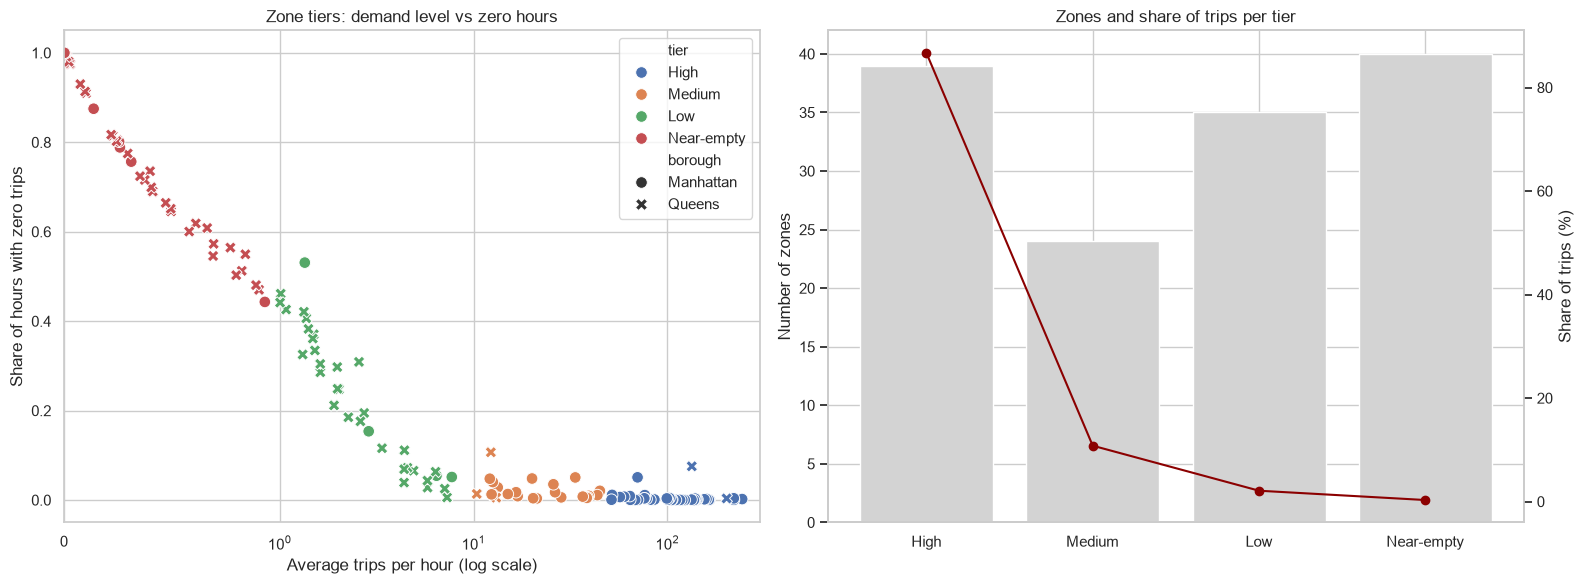

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(data=zone_stats, x="avg_per_hour", y="zero_share", hue="tier",
                hue_order=TIER_ORDER, style="borough", s=70, ax=axes[0])
axes[0].set_xscale("symlog", linthresh=1)
axes[0].set_xlim(0, 300)
axes[0].set_xlabel("Average trips per hour (log scale)")
axes[0].set_ylabel("Share of hours with zero trips")
axes[0].set_title("Zone tiers: demand level vs zero hours")

axes[1].bar(tier_summary.index, tier_summary["zones"], color="lightgray", label="Number of zones")
axes[1].set_ylabel("Number of zones")
ax2 = axes[1].twinx()
ax2.plot(tier_summary.index, tier_summary["share_of_trips_%"], color="darkred", marker="o", label="Share of trips (%)")
ax2.set_ylabel("Share of trips (%)")
ax2.grid(False)
axes[1].set_title("Zones and share of trips per tier")

save_fig("C7_zone_tiers")

**Finding (C7):** 39 **High** zones (37 in Manhattan) carry **86.7%** of trips and almost never have a zero hour. 40 **Near-empty** zones (32 in Queens) carry only 0.3% of trips and have zero trips in 74% of hours. Models should treat near-empty zones separately (or leave them out), because their demand is mostly zeros.

## C8. Zone clustering by weekly demand profile

Each zone gets a **weekly profile**: its average trips for each of the 168 hours of the week (7 days x 24 hours). Each profile is divided by its own total, so the clustering compares the **shape** of the week, not the size of the zone. Holidays are left out so they do not distort the normal week.

Near-empty zones are not clustered because their profiles are mostly zeros.

In [15]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

active_ids = zone_stats[zone_stats["tier"] != "Near-empty"]["PULocationID"]
normal_days = df[(df["is_holiday"] == False) & (df["PULocationID"].isin(active_ids))]

# Rows = zones, columns = (day_of_week, hour) -> 168 columns
weekly = normal_days.groupby(["PULocationID", "day_of_week", "hour"])["trip_count"].mean().unstack(["day_of_week", "hour"])

# Turn each row into shares so that only the shape matters
weekly_shape = weekly.div(weekly.sum(axis=1), axis=0)
print("Zones clustered:", weekly_shape.shape[0], "| profile length:", weekly_shape.shape[1])

Zones clustered: 98 | profile length: 168


k = 2 | silhouette = 0.276
k = 3 | silhouette = 0.301
k = 4 | silhouette = 0.266
k = 5 | silhouette = 0.232
k = 6 | silhouette = 0.236
k = 7 | silhouette = 0.22
k = 8 | silhouette = 0.219


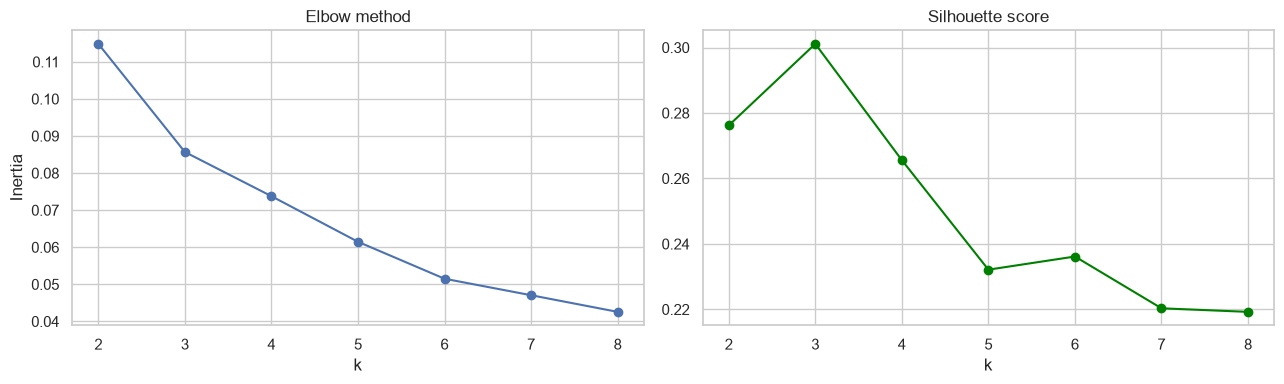

In [16]:
# Try k = 2 to 8 and compare inertia (elbow) and silhouette score
k_values = range(2, 9)
inertias = []
silhouettes = []
for k in k_values:
    model = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = model.fit_predict(weekly_shape)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(weekly_shape, labels))
    print("k =", k, "| silhouette =", round(silhouettes[-1], 3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")
axes[1].plot(list(k_values), silhouettes, marker="o", color="green")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("k")
save_fig("C8_choosing_k")

In [17]:
# k = 3 has the highest silhouette score. k = 4 only splits off a single zone (Maspeth),
# so 3 clusters is the clearest grouping.
K = 3

# Names chosen after looking at the weekly shapes and the zones in each cluster below
CLUSTER_NAMES = {
    0: "Residential (morning commute)",
    1: "Nightlife (late night and weekends)",
    2: "Core business and airports (daytime)",
}

kmeans = KMeans(n_clusters=K, n_init=20, random_state=42)
cluster_ids = kmeans.fit_predict(weekly_shape)
cluster_table = pd.DataFrame({"PULocationID": weekly_shape.index, "cluster": cluster_ids})
cluster_table = cluster_table.merge(zone_stats[["PULocationID", "zone_name", "zone_label", "borough",
                                                "service_zone", "total_trips", "tier"]], on="PULocationID")

# Show the busiest zones in each cluster to help name it
for c in range(K):
    members = cluster_table[cluster_table["cluster"] == c].sort_values("total_trips", ascending=False)
    print(CLUSTER_NAMES[c], "-", len(members), "zones:", ", ".join(members["zone_name"].head(8)))

Residential (morning commute) - 30 zones: Yorkville East, East Harlem North, Central Harlem North, Washington Heights South, Astoria, Hamilton Heights, Sunnyside, Jackson Heights
Nightlife (late night and weekends) - 10 zones: East Village, West Village, Greenwich Village South, Lower East Side, Little Italy/NoLiTa, Meatpacking/West Village West, Alphabet City, Seaport
Core business and airports (daytime) - 58 zones: Upper East Side South, Midtown Center, Upper East Side North, JFK Airport, Penn Station/Madison Sq West, Midtown East, Lincoln Square East, Times Sq/Theatre District


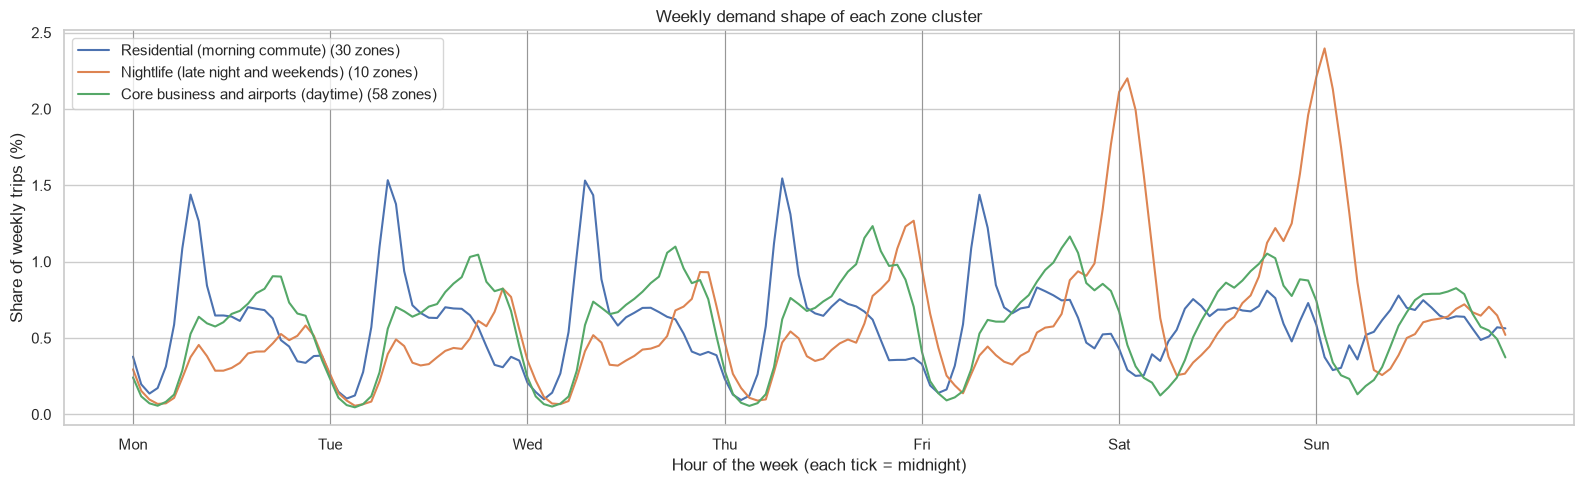

In [18]:
# Average weekly shape of each cluster
fig, ax = plt.subplots(figsize=(16, 5))
for c in range(K):
    member_ids = cluster_table[cluster_table["cluster"] == c]["PULocationID"]
    avg_shape = weekly_shape.loc[member_ids].mean() * 100
    ax.plot(range(168), avg_shape.values, label=CLUSTER_NAMES[c] + " (" + str(len(member_ids)) + " zones)")

ax.set_xticks(range(0, 168, 24))
ax.set_xticklabels(DAY_NAMES)
for x in range(0, 168, 24):
    ax.axvline(x, color="gray", linewidth=0.5)
ax.set_xlabel("Hour of the week (each tick = midnight)")
ax.set_ylabel("Share of weekly trips (%)")
ax.set_title("Weekly demand shape of each zone cluster")
ax.legend()
save_fig("C8_cluster_weekly_profiles")

In [19]:
cluster_table["cluster_name"] = cluster_table["cluster"].map(CLUSTER_NAMES)

cluster_summary = cluster_table.groupby("cluster_name").agg(
    zones=("PULocationID", "count"),
    manhattan=("borough", lambda s: (s == "Manhattan").sum()),
    queens=("borough", lambda s: (s == "Queens").sum()),
    total_trips=("total_trips", "sum"),
)
cluster_summary["share_of_trips_%"] = (cluster_summary["total_trips"] / zone_stats["total_trips"].sum() * 100).round(1)
cluster_summary

,zones,manhattan,queens,total_trips,share_of_trips_%
cluster_name,,,,,
Core business and airports (daytime),58,46,12,18314351,84.3
Nightlife (late night and weekends),10,8,2,2315770,10.7
Residential (morning commute),30,7,23,1033127,4.8


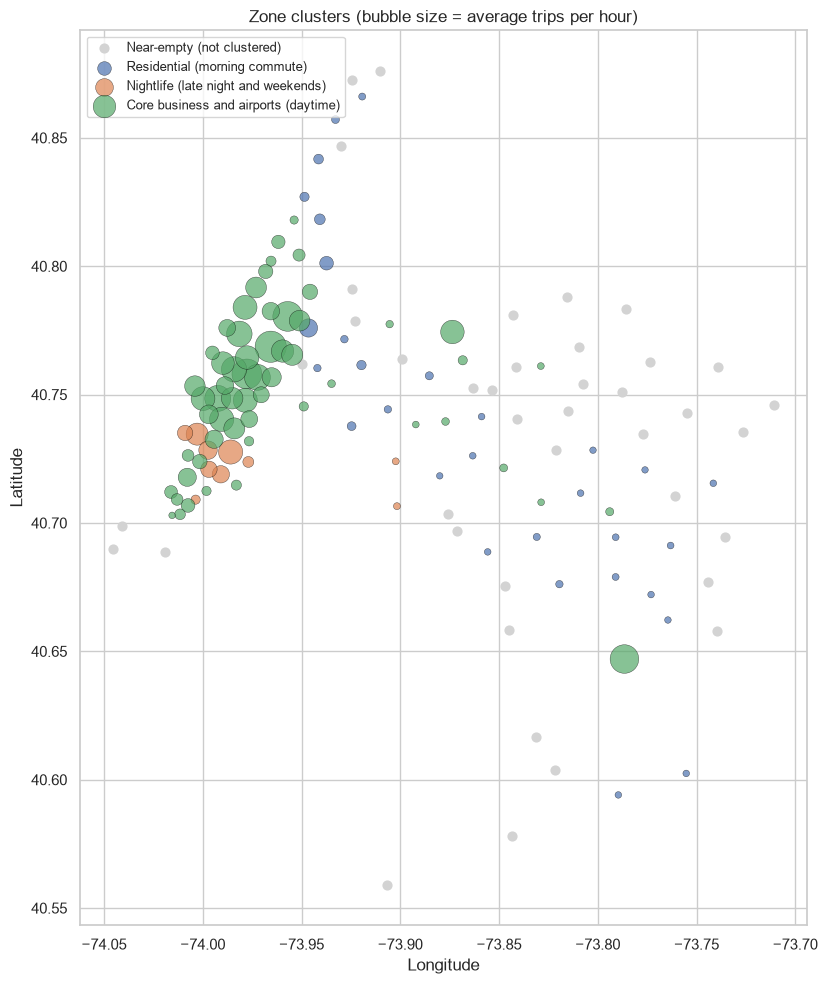

In [20]:
# Map of the clusters (near-empty zones in light gray)
map_data = zone_stats.merge(cluster_table[["PULocationID", "cluster_name"]], on="PULocationID", how="left")
map_data["cluster_name"] = map_data["cluster_name"].fillna("Near-empty (not clustered)")

plt.figure(figsize=(10, 10))
empty = map_data[map_data["cluster_name"] == "Near-empty (not clustered)"]
plt.scatter(empty["longitude"], empty["latitude"], color="lightgray", s=40, label="Near-empty (not clustered)")

for name in CLUSTER_NAMES.values():
    data = map_data[map_data["cluster_name"] == name]
    plt.scatter(data["longitude"], data["latitude"], s=data["avg_per_hour"] * 2 + 20,
                alpha=0.7, edgecolor="black", linewidth=0.3, label=name)

plt.gca().set_aspect(1.3)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Zone clusters (bubble size = average trips per hour)")
plt.legend(loc="upper left", fontsize=9)
save_fig("C8_cluster_map")

**Finding (C8):** Three zone types (k = 3, best silhouette score of 0.30):

| Cluster | Zones | Share of trips | Weekly shape |
|---|---|---|---|
| Core business and airports (daytime) | 58 | 84.3% | Builds through the day, peaks in the afternoon and early evening |
| Nightlife (late night and weekends) | 10 | 10.7% | Small on weekdays, very large peaks on Friday and Saturday nights |
| Residential (morning commute) | 30 | 4.8% | Sharp weekday peak at 07–09, mostly upper Manhattan and Queens neighbourhoods |

The cluster can be used as a model feature, or to train one model per zone type.

## C10. Demand correlation between zones

Correlation of the hourly trip counts for the 30 busiest zones, ordered by cluster. A high value means the two zones rise and fall together during the day and week.

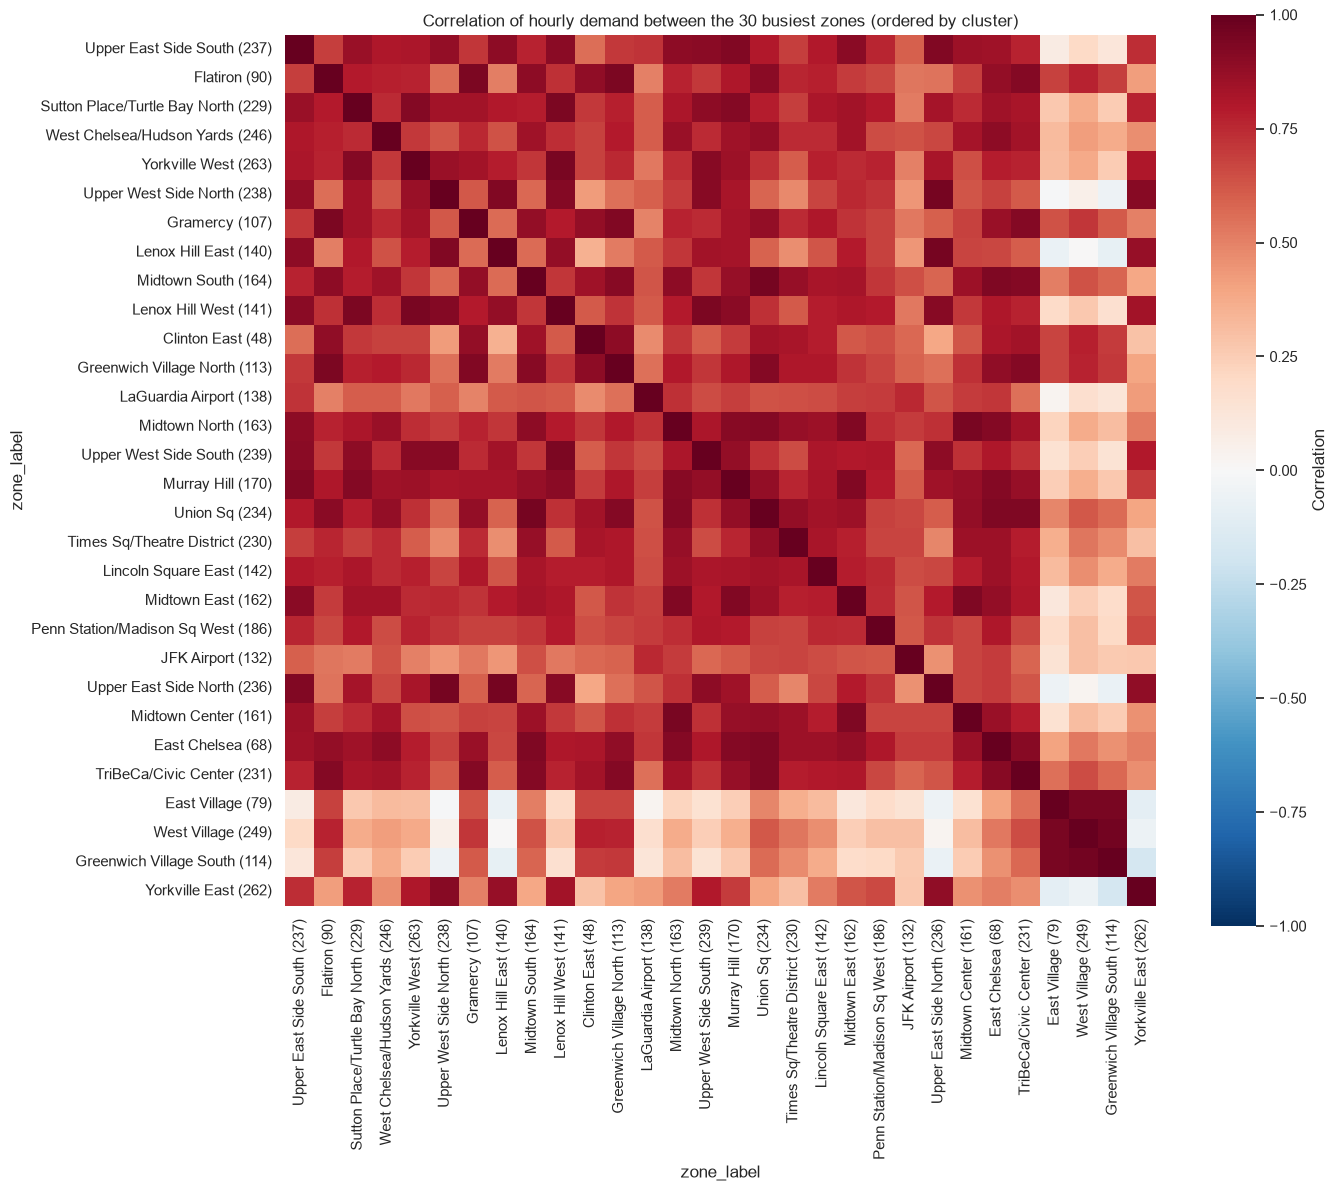

In [21]:
top30 = zone_stats.head(30)[["PULocationID", "zone_label"]].merge(cluster_table[["PULocationID", "cluster_name"]], on="PULocationID")
top30 = top30.sort_values("cluster_name")

hourly_top30 = df[df["PULocationID"].isin(top30["PULocationID"])].pivot_table(
    index="pickup_hour", columns="zone_label", values="trip_count")
hourly_top30 = hourly_top30[top30["zone_label"]]   # order the columns by cluster

zone_corr = hourly_top30.corr()

plt.figure(figsize=(14, 12))
sns.heatmap(zone_corr, cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            cbar_kws={"label": "Correlation"}, xticklabels=True, yticklabels=True)
plt.title("Correlation of hourly demand between the 30 busiest zones (ordered by cluster)")
save_fig("C10_zone_correlation_heatmap")

In [22]:
# Average correlation for pairs in the same cluster vs different clusters
same_cluster = []
diff_cluster = []
labels = list(top30["zone_label"])
clusters = list(top30["cluster_name"])
for i in range(len(labels)):
    for j in range(i + 1, len(labels)):
        value = zone_corr.loc[labels[i], labels[j]]
        if clusters[i] == clusters[j]:
            same_cluster.append(value)
        else:
            diff_cluster.append(value)

print("Average correlation, same cluster:     ", round(np.mean(same_cluster), 2))
print("Average correlation, different cluster:", round(np.mean(diff_cluster), 2))

Average correlation, same cluster:      0.75
Average correlation, different cluster: 0.38


**Finding (C10):** Zones in the same cluster move together (average correlation **0.75**), much more than zones in different clusters (**0.38**). Zones of the same type can share information in a model.

## H1. Variability per zone

Coefficient of variation (CV) = standard deviation / mean of hourly trips. A higher CV means the zone's demand jumps around more relative to its size.

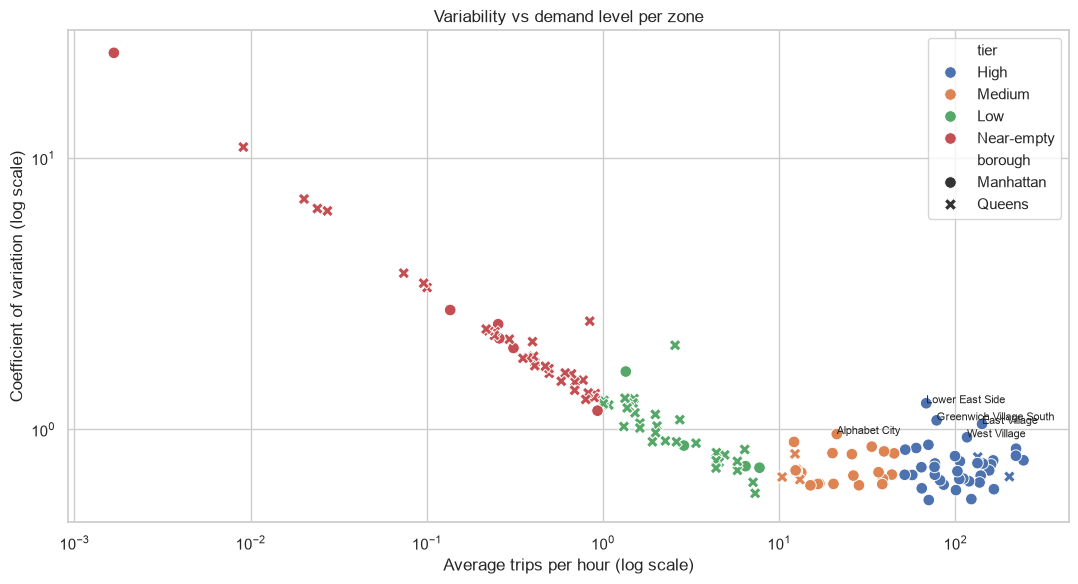

In [23]:
zone_std = df.groupby("PULocationID")["trip_count"].std().rename("std_per_hour").reset_index()
zone_stats = zone_stats.merge(zone_std, on="PULocationID")
zone_stats["cv"] = zone_stats["std_per_hour"] / zone_stats["avg_per_hour"]

plot_data = zone_stats[zone_stats["avg_per_hour"] > 0]

plt.figure(figsize=(11, 6))
sns.scatterplot(data=plot_data, x="avg_per_hour", y="cv", hue="tier", hue_order=TIER_ORDER, style="borough", s=70)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Average trips per hour (log scale)")
plt.ylabel("Coefficient of variation (log scale)")
plt.title("Variability vs demand level per zone")

# Label the 5 most variable zones among High and Medium tier
busy = plot_data[plot_data["tier"].isin(["High", "Medium"])].sort_values("cv", ascending=False).head(5)
for _, row in busy.iterrows():
    plt.annotate(row["zone_name"], (row["avg_per_hour"], row["cv"]), fontsize=8)
save_fig("H1_cv_vs_mean")

In [24]:
print("Median CV by tier:")
print(zone_stats.groupby("tier")["cv"].median().reindex(TIER_ORDER).round(2))
print()
print("Most variable High/Medium zones:")
print(busy[["zone_label", "avg_per_hour", "cv"]].round(2).to_string(index=False))

Median CV by tier:
tier
High          0.73
Medium        0.70
Low           0.97
Near-empty    1.93
Name: cv, dtype: float64

Most variable High/Medium zones:
                   zone_label  avg_per_hour   cv
        Lower East Side (148)         68.23 1.25
Greenwich Village South (114)         78.16 1.08
            East Village (79)        141.47 1.05
            Alphabet City (4)         21.21 0.96
           West Village (249)        116.28 0.94


**Finding (H1):** Busy zones are more stable relative to their size (median CV of about 0.7) than quiet ones (Near-empty median CV of 1.93). Among busy zones, the most variable are the **nightlife zones**: Lower East Side, Greenwich Village South and East Village, because of their big weekend-night peaks.

## H2. Demand pattern classes (Syntetos–Boylan)

Two numbers per zone:

- **ADI** (average demand interval): hours in the period / hours with at least one trip. ADI = 1 means a trip every hour.
- **CV²**: squared CV of the hours that do have trips. A high CV² means very uneven sizes.

| | CV² < 0.49 | CV² ≥ 0.49 |
|---|---|---|
| **ADI < 1.32** | Smooth | Erratic |
| **ADI ≥ 1.32** | Intermittent | Lumpy |

In [25]:
ADI_CUT = 1.32
CV2_CUT = 0.49

rows = []
for zone_id, group in df.groupby("PULocationID"):
    counts = group["trip_count"]
    nonzero = counts[counts > 0]

    if len(nonzero) < 2:
        rows.append({"PULocationID": zone_id, "adi": np.nan, "cv2": np.nan, "demand_class": "No demand"})
        continue

    adi = len(counts) / len(nonzero)
    cv2 = (nonzero.std() / nonzero.mean()) ** 2

    if adi < ADI_CUT and cv2 < CV2_CUT:
        demand_class = "Smooth"
    elif adi < ADI_CUT:
        demand_class = "Erratic"
    elif cv2 < CV2_CUT:
        demand_class = "Intermittent"
    else:
        demand_class = "Lumpy"

    rows.append({"PULocationID": zone_id, "adi": adi, "cv2": cv2, "demand_class": demand_class})

sb_table = pd.DataFrame(rows)
zone_stats = zone_stats.merge(sb_table, on="PULocationID")

print(zone_stats["demand_class"].value_counts())
print()
print(pd.crosstab(zone_stats["tier"], zone_stats["demand_class"]).reindex(TIER_ORDER))

demand_class
Smooth          46
Intermittent    43
Erratic         35
Lumpy           12
No demand        2
Name: count, dtype: int64

demand_class  Erratic  Intermittent  Lumpy  No demand  Smooth
tier                                                         
High               21             0      0          0      18
Medium              7             0      0          0      17
Low                 7             7     10          0      11
Near-empty          0            36      2          2       0


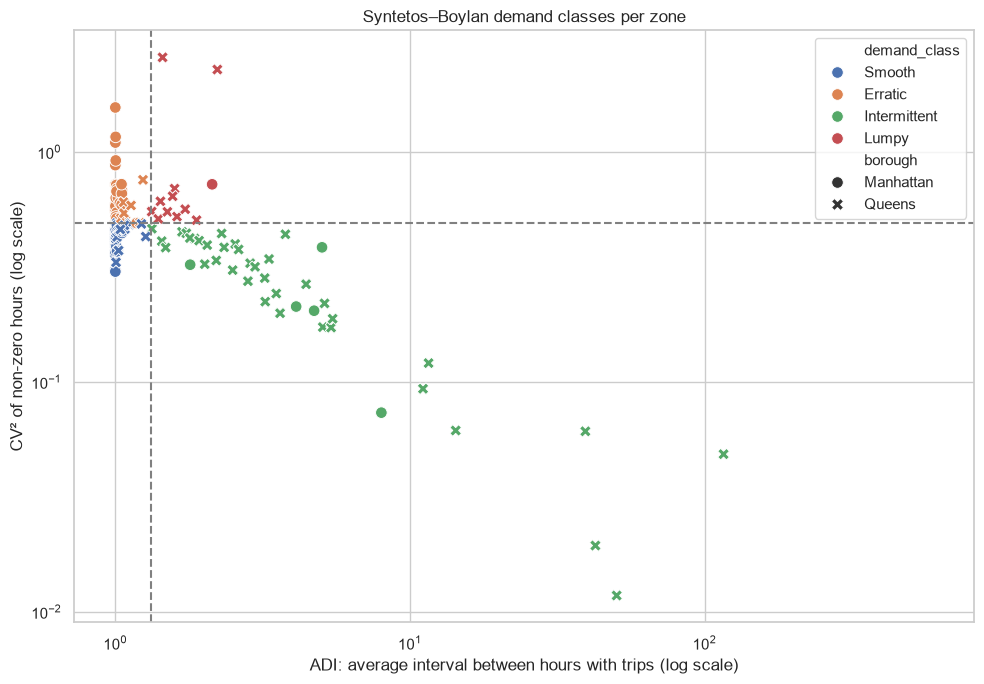

In [26]:
CLASS_ORDER = ["Smooth", "Erratic", "Intermittent", "Lumpy"]
plot_data = zone_stats[zone_stats["demand_class"] != "No demand"]

plt.figure(figsize=(10, 7))
sns.scatterplot(data=plot_data, x="adi", y="cv2", hue="demand_class", hue_order=CLASS_ORDER, style="borough", s=70)
plt.axvline(ADI_CUT, color="gray", linestyle="--")
plt.axhline(CV2_CUT, color="gray", linestyle="--")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("ADI: average interval between hours with trips (log scale)")
plt.ylabel("CV² of non-zero hours (log scale)")
plt.title("Syntetos–Boylan demand classes per zone")
save_fig("H2_demand_classes")

**Finding (H2):** 46 zones are Smooth, 35 Erratic, 43 Intermittent and 12 Lumpy (2 have no demand). **Every High and Medium zone is Smooth or Erratic**, so standard count models suit them. Almost all Near-empty zones (36 of 40) are Intermittent, meaning many hours with no trips, so they need a zero-aware approach or should be grouped.

## H6. Predictability by hour and weekday

For each hour-of-week slot (for example Monday 08:00), the CV of the total trips across all weeks. A low value means that slot looks almost the same every week. Holidays and the DST hour are left out.

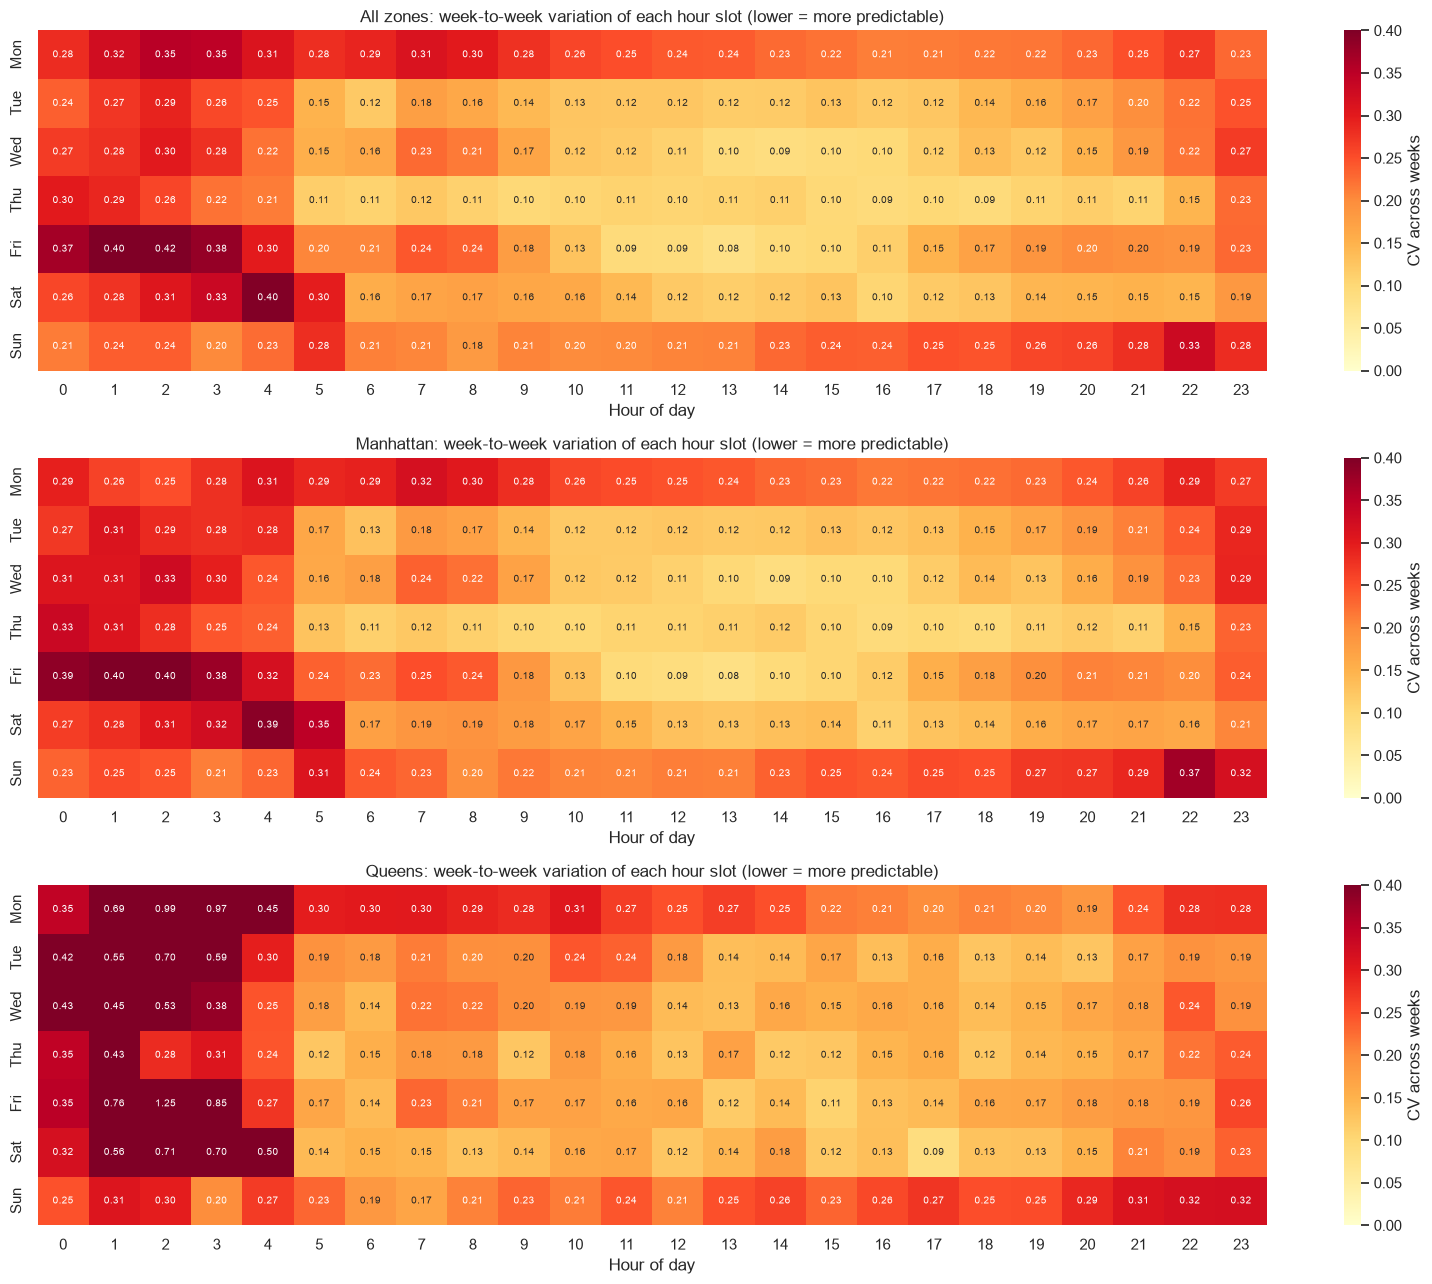

In [27]:
normal_hours = df[(df["is_holiday"] == False) & (df["is_dst_hour"] == False)]


def slot_cv_table(data):
    # Total trips per clock hour, then CV of each (weekday, hour) slot across weeks
    totals = data.groupby(["pickup_hour", "day_of_week", "hour"])["trip_count"].sum().reset_index()
    cv = totals.groupby(["day_of_week", "hour"])["trip_count"].agg(lambda s: s.std() / s.mean())
    table = cv.unstack("hour")
    table.index = DAY_NAMES
    return table


fig, axes = plt.subplots(3, 1, figsize=(16, 13))
groups = {
    "All zones": normal_hours,
    "Manhattan": normal_hours[normal_hours["borough"] == "Manhattan"],
    "Queens": normal_hours[normal_hours["borough"] == "Queens"],
}
slot_cv = {}
for i, (name, data) in enumerate(groups.items()):
    slot_cv[name] = slot_cv_table(data)
    sns.heatmap(slot_cv[name], cmap="YlOrRd", annot=True, fmt=".2f", annot_kws={"size": 7},
                vmin=0, vmax=0.4, ax=axes[i], cbar_kws={"label": "CV across weeks"})
    axes[i].set_title(name + ": week-to-week variation of each hour slot (lower = more predictable)")
    axes[i].set_xlabel("Hour of day")
    axes[i].set_ylabel("")
save_fig("H6_predictability_heatmap")

In [28]:
all_cv = slot_cv["All zones"].stack()
print("Most predictable slots:")
print(all_cv.sort_values().head(5).round(3))
print()
print("Least predictable slots:")
print(all_cv.sort_values(ascending=False).head(5).round(3))
print()
print("Average slot CV  -  Manhattan:", round(slot_cv["Manhattan"].values.mean(), 3),
      "| Queens:", round(slot_cv["Queens"].values.mean(), 3))

Most predictable slots:
     hour
Fri  13      0.083
Wed  14      0.091
Fri  12      0.094
Thu  18      0.094
     16      0.095
dtype: float64

Least predictable slots:
     hour
Fri  2       0.425
     1       0.402
Sat  4       0.398
Fri  3       0.382
     0       0.370
dtype: float64

Average slot CV  -  Manhattan: 0.206 | Queens: 0.253


**Finding (H6):** **Weekday daytime is the most predictable** (CV of about 0.08–0.10 for Tuesday–Friday, 10:00–18:00). **Late nights are the least predictable**, especially early Friday and Saturday (CV up to 0.4). Mondays and Sundays vary more than mid-week days, possibly because of the days around holidays (checked in #60). Queens varies more than Manhattan (average slot CV of 0.25 vs 0.21), and its night hours are very unstable.

### Key takeaways from section 1 (#59)

1. Demand is highly concentrated: 16 zones make up half of all trips, and Manhattan has 91% of them.
2. Three zone types exist (core daytime, nightlife, residential commute), each with its own weekly shape.
3. 40 zones are near-empty and intermittent. They need separate handling in modelling.
4. Weekday daytime demand is very predictable. Late nights and Queens are the hardest to forecast.

## Save the zone tables

Saved for the other EDA sections, modelling and the dashboard.

In [29]:
tier_columns = ["PULocationID", "zone_name", "borough", "service_zone", "total_trips",
                "avg_per_hour", "zero_share", "tier", "cv", "adi", "cv2", "demand_class"]
zone_stats[tier_columns].round(4).to_csv(TABLE_DIR + "/zone_tiers.csv", index=False)

clusters_out = zone_stats[["PULocationID", "zone_name", "borough", "service_zone", "tier"]].merge(
    cluster_table[["PULocationID", "cluster", "cluster_name"]], on="PULocationID", how="left")
clusters_out["cluster"] = clusters_out["cluster"].astype("Int64")   # whole numbers; blank for near-empty zones
clusters_out["cluster_name"] = clusters_out["cluster_name"].fillna("Near-empty (not clustered)")
clusters_out.to_csv(TABLE_DIR + "/zone_clusters.csv", index=False)

print("Saved zone_tiers.csv and zone_clusters.csv")

Saved zone_tiers.csv and zone_clusters.csv
